In [1]:
# Part B : EDA Analysis 
# Import the Pandas library
import pandas as pd

# Load the training and testing datasets
train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

# Display the dataset dimensions
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

# Preview the first five training records
train_df.head()

Training dataset: (103904, 25)
Testing dataset: (25976, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [2]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      1039

In [3]:
# Check missing values
train_df.isnull().sum()

Unnamed: 0                             0
id                                     0
Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             310
satisfaction    

In [4]:
# Check potential duplicates without ID columns
duplicates = train_df.drop(columns=["Unnamed: 0", "id"]).duplicated().sum()

print("Potential duplicate records:", duplicates)

Potential duplicate records: 0


satisfaction
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64


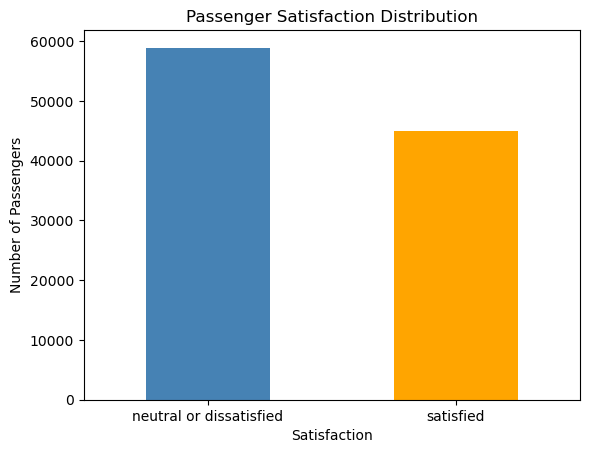

In [5]:
# Count satisfaction categories
print(train_df["satisfaction"].value_counts())

# Plot satisfaction distribution
import matplotlib.pyplot as plt

train_df["satisfaction"].value_counts().plot(
    kind="bar",
    color=["steelblue", "orange"]
)

plt.title("Passenger Satisfaction Distribution")
plt.xlabel("Satisfaction")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.show()

In [6]:
# Descriptive statistics
columns = ["Age", "Flight Distance",
           "Departure Delay in Minutes",
           "Arrival Delay in Minutes"]

train_df[columns].describe().round(2)

,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
count,103904.00,103904.00,103904.00,103594.00
mean,39.38,1189.45,14.82,15.18
std,15.11,997.15,38.23,38.70
min,7.00,31.00,0.00,0.00
25%,27.00,414.00,0.00,0.00
50%,40.00,843.00,0.00,0.00
75%,51.00,1743.00,12.00,13.00
max,85.00,4983.00,1592.00,1584.00


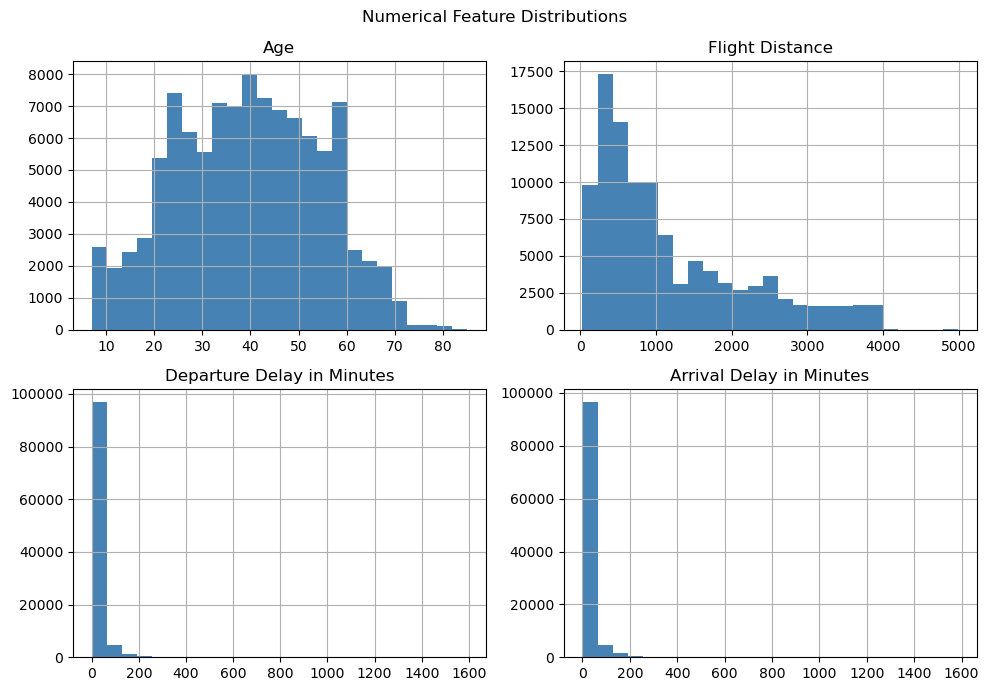

In [7]:
# Feature distributions
import matplotlib.pyplot as plt

train_df[columns].hist(
    figsize=(10, 7),
    bins=25,
    color="steelblue"
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

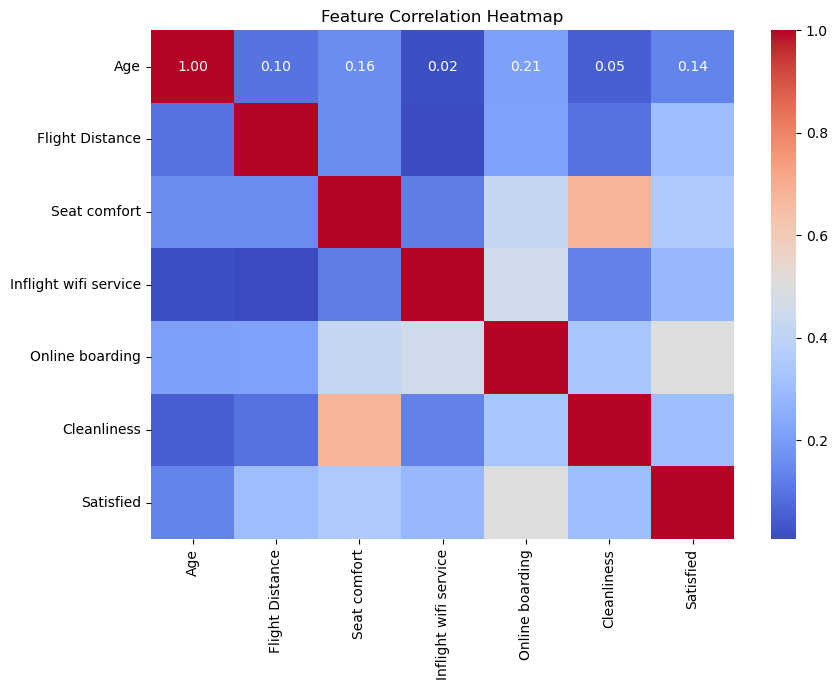

In [8]:
# Correlation analysis
import seaborn as sns

features = ["Age", "Flight Distance", "Seat comfort",
            "Inflight wifi service", "Online boarding",
            "Cleanliness"]

corr_data = train_df[features].copy()
corr_data["Satisfied"] = (
    train_df["satisfaction"] == "satisfied"
).astype(int)

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

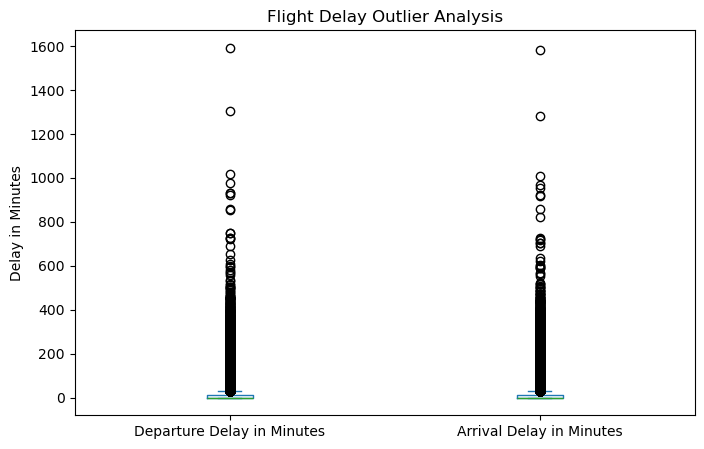

In [9]:
# Outlier analysis
train_df[
    ["Departure Delay in Minutes",
     "Arrival Delay in Minutes"]
].plot(kind="box", figsize=(8, 5))

plt.title("Flight Delay Outlier Analysis")
plt.ylabel("Delay in Minutes")
plt.show()

satisfaction  neutral or dissatisfied  satisfied
Class                                           
Business                        30.57      69.43
Eco                             81.39      18.61
Eco Plus                        75.39      24.61


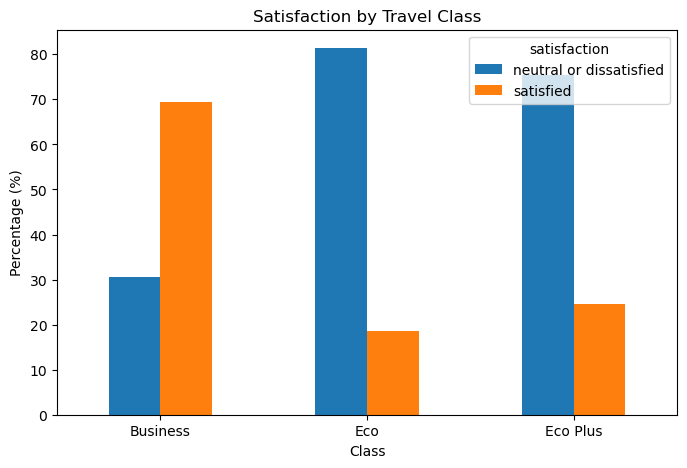

In [10]:
# Satisfaction by travel class
class_data = pd.crosstab(
    train_df["Class"],
    train_df["satisfaction"],
    normalize="index"
) * 100

print(class_data.round(2))

class_data.plot(kind="bar", figsize=(8, 5))
plt.title("Satisfaction by Travel Class")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.show()

satisfaction     neutral or dissatisfied  satisfied
Type of Travel                                     
Business travel                    41.74      58.26
Personal Travel                    89.83      10.17


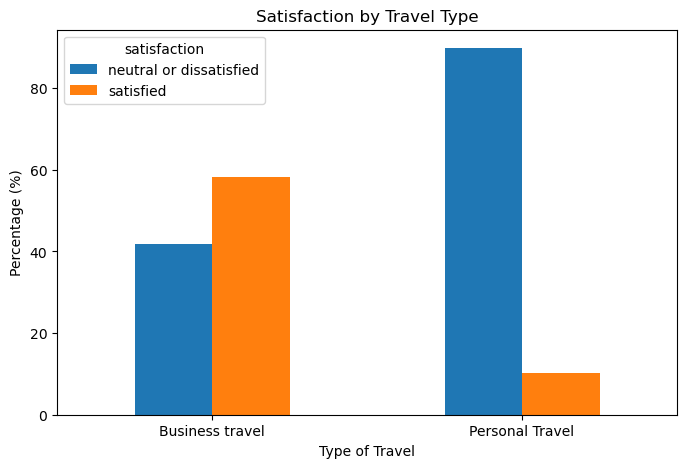

In [11]:
# Satisfaction by travel type
travel_data = pd.crosstab(
    train_df["Type of Travel"],
    train_df["satisfaction"],
    normalize="index"
) * 100

print(travel_data.round(2))

travel_data.plot(kind="bar", figsize=(8, 5))
plt.title("Satisfaction by Travel Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.show()

                         Seat comfort  Inflight wifi service  Online boarding  \
satisfaction                                                                    
neutral or dissatisfied          3.04                   2.40             2.66   
satisfied                        3.97                   3.16             4.03   

                         Cleanliness  
satisfaction                          
neutral or dissatisfied         2.94  
satisfied                       3.74  


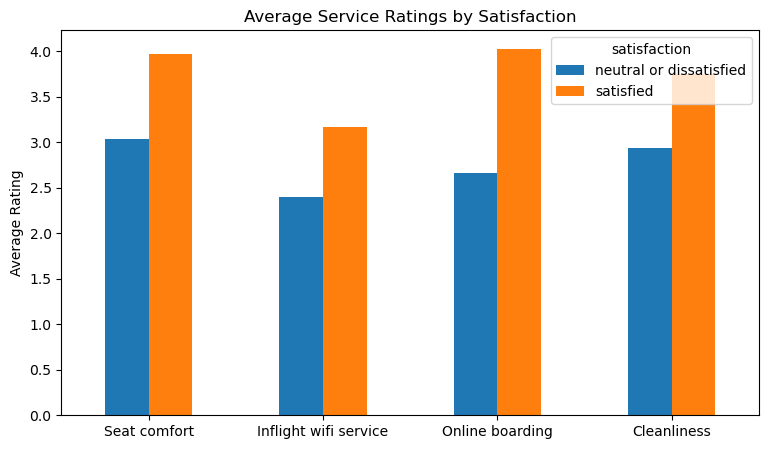

In [12]:
# Average service ratings
services = ["Seat comfort", "Inflight wifi service",
            "Online boarding", "Cleanliness"]

ratings = train_df.groupby("satisfaction")[services].mean()

print(ratings.round(2))

ratings.T.plot(kind="bar", figsize=(9, 5))
plt.title("Average Service Ratings by Satisfaction")
plt.ylabel("Average Rating")
plt.xticks(rotation=0)
plt.show()

In [13]:
# Check zero service ratings
zero_ratings = (train_df[services] == 0).sum()

print("Zero ratings by service:")
print(zero_ratings)

Zero ratings by service:
Seat comfort                1
Inflight wifi service    3103
Online boarding          2428
Cleanliness                12
dtype: int64


In [14]:
# Part C : Data Preparation
# Separate features and target
X_train = train_df.drop(
    columns=["Unnamed: 0", "id", "satisfaction"]
).copy()

X_test = test_df.drop(
    columns=["Unnamed: 0", "id", "satisfaction"]
).copy()

y_train = (train_df["satisfaction"] == "satisfied").astype(int)
y_test = (test_df["satisfaction"] == "satisfied").astype(int)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (103904, 22)
Testing features: (25976, 22)


In [15]:
# Create a new delay feature
X_train["Delay Change"] = (
    X_train["Arrival Delay in Minutes"]
    - X_train["Departure Delay in Minutes"]
)

X_test["Delay Change"] = (
    X_test["Arrival Delay in Minutes"]
    - X_test["Departure Delay in Minutes"]
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

X_train[["Delay Change"]].head()

Training features: (103904, 23)
Testing features: (25976, 23)


,Delay Change
0,-7.0
1,5.0
2,0.0
3,-2.0
4,0.0


In [16]:
# Identify feature types
categorical_cols = X_train.select_dtypes(
    include="object"
).columns.tolist()

numeric_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

print("Categorical features:", categorical_cols)
print("Number of numerical features:", len(numeric_cols))

Categorical features: ['Gender', 'Customer Type', 'Type of Travel', 'Class']
Number of numerical features: 19


In [17]:
# Import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [18]:
# Check class distribution
print("Class counts:")
print(y_train.value_counts())

print("\nClass percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Class counts:
satisfaction
0    58879
1    45025
Name: count, dtype: int64

Class percentages:
satisfaction
0    56.67
1    43.33
Name: proportion, dtype: float64


In [19]:
# Check constant features
constant_cols = X_train.columns[
    X_train.nunique(dropna=False) <= 1
]

print("Constant features:", constant_cols.tolist())

Constant features: []


In [20]:
# Test preprocessing on a sample
from sklearn.base import clone

sample = X_train.sample(1000, random_state=42)

processed_sample = clone(preprocessor).fit_transform(sample)

print("Before preprocessing:", sample.shape)
print("After preprocessing:", processed_sample.shape)

Before preprocessing: (1000, 23)
After preprocessing: (1000, 28)


In [21]:
# Prepare features without the engineered column
X_train_original = X_train.drop(columns=["Delay Change"])

print("Original feature count:", X_train_original.shape[1])
print("Engineered feature count:", X_train.shape[1])

Original feature count: 22
Engineered feature count: 23


In [22]:
# Apply preprocessing
from sklearn.base import clone

fitted_preprocessor = clone(preprocessor)

X_train_processed = fitted_preprocessor.fit_transform(X_train)
X_test_processed = fitted_preprocessor.transform(X_test)

print("Processed training:", X_train_processed.shape)
print("Processed testing:", X_test_processed.shape)

Processed training: (103904, 28)
Processed testing: (25976, 28)


In [23]:
# Convert processed data to DataFrames
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()
    X_test_processed = X_test_processed.toarray()

feature_names = fitted_preprocessor.get_feature_names_out()

processed_train_df = pd.DataFrame(
    X_train_processed, columns=feature_names
)

processed_test_df = pd.DataFrame(
    X_test_processed, columns=feature_names
)

# Add target variable
processed_train_df["satisfaction"] = y_train.to_numpy()
processed_test_df["satisfaction"] = y_test.to_numpy()

print("Training:", processed_train_df.shape)
print("Testing:", processed_test_df.shape)

processed_train_df.iloc[:5, :6]

Training: (103904, 29)
Testing: (25976, 29)


,num__Age,num__Flight Distance,num__Inflight wifi service,num__Departure/Arrival time convenient,num__Ease of Online booking,num__Gate location
0,-1.745279,-0.731539,0.203579,0.616172,0.173776,-1.547323
1,-0.951360,-0.957184,0.203579,-0.695245,0.173776,0.018094
2,-0.885200,-0.047584,-0.549533,-0.695245,-0.541060,-0.764614
3,-0.951360,-0.629246,-0.549533,1.271880,1.603448,1.583511
4,1.430397,-0.978244,0.203579,-0.039537,0.173776,0.018094


In [24]:
# Verify missing values
print("Training missing values:",
      processed_train_df.isnull().sum().sum())

print("Testing missing values:",
      processed_test_df.isnull().sum().sum())

Training missing values: 0
Testing missing values: 0


In [25]:
# Save processed datasets
processed_train_df.round(4).to_csv(
    "data/processed_train.csv", index=False
)

processed_test_df.round(4).to_csv(
    "data/processed_test.csv", index=False
)

print("Processed datasets saved successfully!")

Processed datasets saved successfully!


In [26]:
# Part D : Development of Three Base Models
# Split training data for validation
from sklearn.model_selection import train_test_split

X_dev, X_val, y_dev, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Development:", X_dev.shape)
print("Validation:", X_val.shape)

Development: (83123, 23)
Validation: (20781, 23)


In [27]:
# Import classification algorithms - create three base models
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Create three models
models = {
    "Logistic Regression": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("Models created:", list(models.keys()))

Models created: ['Logistic Regression', 'Decision Tree', 'Random Forest']


In [28]:
# Train models and measure time
import time

training_times = {}

for name, model in models.items():
    start = time.perf_counter()

    model.fit(X_dev, y_dev)

    training_times[name] = round(
        time.perf_counter() - start, 2
    )

    print(name, "trained in",
          training_times[name], "seconds")

Logistic Regression trained in 0.82 seconds
Decision Tree trained in 1.37 seconds
Random Forest trained in 5.35 seconds


In [29]:
# Evaluate base models
from sklearn.metrics import (
    accuracy_score, f1_score,
    recall_score, roc_auc_score
)

results = []

for name, model in models.items():
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Train Accuracy": round(model.score(X_dev, y_dev), 3),
        "Val Accuracy": round(accuracy_score(y_val, predictions), 3),
        "Macro F1": round(f1_score(y_val, predictions, average="macro"), 3),
        "Dissatisfied Recall": round(recall_score(y_val, predictions, pos_label=0), 3),
        "ROC-AUC": round(roc_auc_score(y_val, probabilities), 3),
        "Train Time (s)": training_times[name]
    })

baseline_results = pd.DataFrame(results)
display(baseline_results)

,Model,Train Accuracy,Val Accuracy,Macro F1,Dissatisfied Recall,ROC-AUC,Train Time (s)
0,Logistic Regression,0.875,0.877,0.874,0.903,0.928,0.82
1,Decision Tree,1.000,0.944,0.943,0.946,0.944,1.37
2,Random Forest,1.000,0.963,0.963,0.977,0.994,5.35


In [30]:
# Calculate overfitting gap
baseline_results["Overfitting Gap"] = (
    baseline_results["Train Accuracy"]
    - baseline_results["Val Accuracy"]
).round(3)

display(baseline_results[
    ["Model", "Train Accuracy", "Val Accuracy", "Overfitting Gap"]
])

,Model,Train Accuracy,Val Accuracy,Overfitting Gap
0,Logistic Regression,0.875,0.877,-0.002
1,Decision Tree,1.000,0.944,0.056
2,Random Forest,1.000,0.963,0.037


In [31]:
# Preprocessing without Delay Change
numeric_no_delay = [
    c for c in numeric_cols if c != "Delay Change"
]

preprocessor_no_delay = ColumnTransformer([
    ("num", clone(numeric_pipeline), numeric_no_delay),
    ("cat", clone(categorical_pipeline), categorical_cols)
])

# Train without engineered feature
no_delay_model = Pipeline([
    ("preprocessing", preprocessor_no_delay),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

no_delay_model.fit(
    X_dev.drop(columns=["Delay Change"]), y_dev
)

# Compare results
f1_without = f1_score(
    y_val,
    no_delay_model.predict(X_val.drop(columns=["Delay Change"])),
    average="macro"
)

f1_with = f1_score(
    y_val,
    models["Logistic Regression"].predict(X_val),
    average="macro"
)

print("Without Delay Change:", round(f1_without, 3))
print("With Delay Change:", round(f1_with, 3))

Without Delay Change: 0.874
With Delay Change: 0.874


In [32]:
# Logistic Regression with balanced class weights
weighted_lr = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

weighted_lr.fit(X_dev, y_dev)

# Compare with baseline
normal_pred = models["Logistic Regression"].predict(X_val)
weighted_pred = weighted_lr.predict(X_val)

print("Normal Macro F1:",
      round(f1_score(y_val, normal_pred, average="macro"), 3))

print("Balanced Macro F1:",
      round(f1_score(y_val, weighted_pred, average="macro"), 3))

print("Normal Dissatisfied Recall:",
      round(recall_score(y_val, normal_pred, pos_label=0), 3))

print("Balanced Dissatisfied Recall:",
      round(recall_score(y_val, weighted_pred, pos_label=0), 3))

Normal Macro F1: 0.874
Balanced Macro F1: 0.867
Normal Dissatisfied Recall: 0.903
Balanced Dissatisfied Recall: 0.874


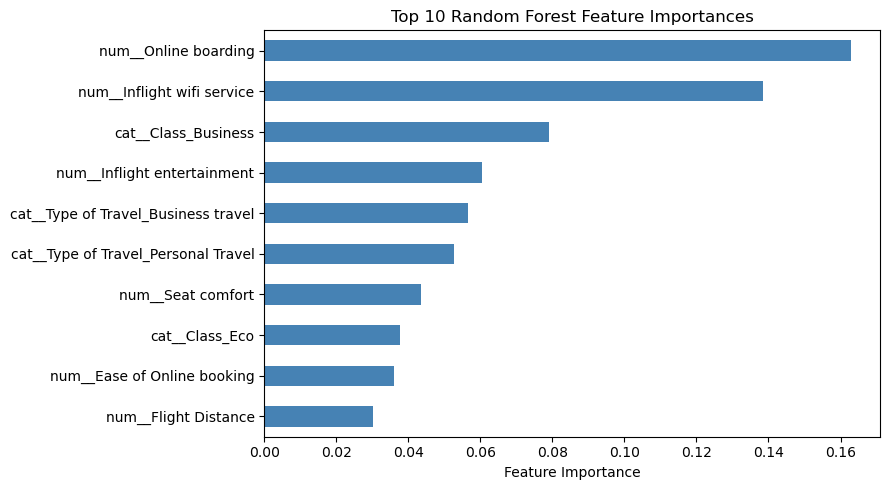

In [33]:
# Random Forest feature importance
rf_model = models["Random Forest"]

feature_names = rf_model.named_steps[
    "preprocessing"
].get_feature_names_out()

importance = rf_model.named_steps[
    "classifier"
].feature_importances_

top_features = pd.Series(
    importance, index=feature_names
).nlargest(10).sort_values()

top_features.plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [34]:
# Part E : Hyperparameter Optimisation
# Import optimisation tools - set up cross validation
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV
)

# Create stratified 3-fold cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("Cross-validation: 3 folds")
print("Optimisation metric: Macro F1")

Cross-validation: 3 folds
Optimisation metric: Macro F1


In [35]:
# Logistic Regression Grid Search
lr_params = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__solver": ["lbfgs", "liblinear"]
}

lr_search = GridSearchCV(
    models["Logistic Regression"],
    lr_params,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1,
    verbose=1
)

lr_search.fit(X_dev, y_dev)

print("Best parameters:", lr_search.best_params_)
print("Best CV Macro F1:", round(lr_search.best_score_, 3))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
Best CV Macro F1: 0.872


In [36]:
# Decision Tree Grid Search
dt_params = {
    "classifier__max_depth": [8, 16, None],
    "classifier__min_samples_leaf": [1, 5, 20]
}

dt_search = GridSearchCV(
    models["Decision Tree"],
    dt_params,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1,
    verbose=1
)

dt_search.fit(X_dev, y_dev)

print("Best parameters:", dt_search.best_params_)
print("Best CV Macro F1:", round(dt_search.best_score_, 3))

Fitting 3 folds for each of 9 candidates, totalling 27 fits
Best parameters: {'classifier__max_depth': 16, 'classifier__min_samples_leaf': 1}
Best CV Macro F1: 0.948


In [37]:
# Random Forest Random Search
rf_params = {
    "classifier__n_estimators": [80, 120, 160],
    "classifier__max_depth": [12, 24, None],
    "classifier__min_samples_leaf": [1, 2, 5]
}

rf_search = RandomizedSearchCV(
    models["Random Forest"],
    rf_params,
    n_iter=6,
    cv=cv,
    scoring="f1_macro",
    random_state=42,
    n_jobs=1,
    verbose=1
)

rf_search.fit(X_dev, y_dev)

print("Best parameters:", rf_search.best_params_)
print("Best CV Macro F1:", round(rf_search.best_score_, 3))

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'classifier__n_estimators': 80, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 24}
Best CV Macro F1: 0.96


In [38]:
# Get the best optimised models
tuned_models = {
    "Logistic Regression": lr_search.best_estimator_,
    "Decision Tree": dt_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_
}

# Evaluate optimised models
tuned_results = []

for name, model in tuned_models.items():
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:, 1]

    tuned_results.append({
        "Model": name,
        "Val Accuracy": round(accuracy_score(y_val, pred), 3),
        "Macro F1": round(f1_score(y_val, pred, average="macro"), 3),
        "Dissatisfied Recall": round(recall_score(y_val, pred, pos_label=0), 3),
        "ROC-AUC": round(roc_auc_score(y_val, prob), 3)
    })

tuned_results = pd.DataFrame(tuned_results)

display(tuned_results)

,Model,Val Accuracy,Macro F1,Dissatisfied Recall,ROC-AUC
0,Logistic Regression,0.877,0.874,0.903,0.928
1,Decision Tree,0.955,0.954,0.968,0.972
2,Random Forest,0.963,0.962,0.976,0.994


In [39]:
# Compare baseline and optimised Macro F1
comparison = baseline_results[
    ["Model", "Macro F1"]
].merge(
    tuned_results[["Model", "Macro F1"]],
    on="Model",
    suffixes=("_Before", "_After")
)

# Calculate improvement
comparison["Improvement"] = (
    comparison["Macro F1_After"]
    - comparison["Macro F1_Before"]
).round(3)

display(comparison)

,Model,Macro F1_Before,Macro F1_After,Improvement
0,Logistic Regression,0.874,0.874,0.000
1,Decision Tree,0.943,0.954,0.011
2,Random Forest,0.963,0.962,-0.001


In [40]:
# Check training and validation accuracy
for name, model in tuned_models.items():
    train_acc = model.score(X_dev, y_dev)
    val_acc = model.score(X_val, y_val)

    print(name)
    print("Training Accuracy:", round(train_acc, 3))
    print("Validation Accuracy:", round(val_acc, 3))
    print("Overfitting Gap:", round(train_acc - val_acc, 3))
    print()

Logistic Regression
Training Accuracy: 0.875
Validation Accuracy: 0.877
Overfitting Gap: -0.002

Decision Tree
Training Accuracy: 0.978
Validation Accuracy: 0.955
Overfitting Gap: 0.023

Random Forest
Training Accuracy: 0.999
Validation Accuracy: 0.963
Overfitting Gap: 0.036



In [41]:
# Summarise hyperparameter optimisation
tuning_summary = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Method": [
        "Grid Search",
        "Grid Search",
        "Random Search"
    ],
    "Best CV F1": [
        lr_search.best_score_,
        dt_search.best_score_,
        rf_search.best_score_
    ],
    "Best Parameters": [
        str(lr_search.best_params_),
        str(dt_search.best_params_),
        str(rf_search.best_params_)
    ]
})

tuning_summary["Best CV F1"] = (
    tuning_summary["Best CV F1"].round(3)
)

display(tuning_summary)

,Model,Method,Best CV F1,Best Parameters
0,Logistic Regression,Grid Search,0.872,"{'classifier__C': 1, 'classifier__solver': 'lb..."
1,Decision Tree,Grid Search,0.948,"{'classifier__max_depth': 16, 'classifier__min..."
2,Random Forest,Random Search,0.960,"{'classifier__n_estimators': 80, 'classifier__..."


In [42]:
# Part F : Ensemble Model Development
# Rank the optimised models

ranking = tuned_results.sort_values(
    "Macro F1",
    ascending=False
)

display(ranking[
    ["Model", "Macro F1", "Dissatisfied Recall"]
])

,Model,Macro F1,Dissatisfied Recall
2,Random Forest,0.962,0.976
1,Decision Tree,0.954,0.968
0,Logistic Regression,0.874,0.903


In [43]:
# Import Voting Classifier
from sklearn.ensemble import VotingClassifier
from sklearn.base import clone

# Equal voting
voting_equal = VotingClassifier(
    estimators=[
        ("dt", clone(tuned_models["Decision Tree"])),
        ("rf", clone(tuned_models["Random Forest"]))
    ],
    voting="soft",
    weights=[1, 1]
)

# Weighted voting
voting_weighted = VotingClassifier(
    estimators=[
        ("dt", clone(tuned_models["Decision Tree"])),
        ("rf", clone(tuned_models["Random Forest"]))
    ],
    voting="soft",
    weights=[1, 2]
)

print("Two voting ensemble models created successfully!")

Two voting ensemble models created successfully!


In [44]:
# Train both ensemble models
import time

ensemble_candidates = {
    "Equal Soft Voting": voting_equal,
    "Weighted Soft Voting": voting_weighted
}

ensemble_times = {}

for name, model in ensemble_candidates.items():

    start = time.perf_counter()

    model.fit(X_dev, y_dev)

    ensemble_times[name] = round(
        time.perf_counter() - start, 2
    )

    print(
        name, "trained in",
        ensemble_times[name], "seconds"
    )

Equal Soft Voting trained in 6.22 seconds
Weighted Soft Voting trained in 5.92 seconds


In [45]:
# Evaluate ensemble models

ensemble_results_list = []

for name, model in ensemble_candidates.items():

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    ensemble_results_list.append({
        "Model": name,
        "Val Accuracy": round(
            accuracy_score(y_val, predictions), 3
        ),
        "Macro F1": round(
            f1_score(y_val, predictions, average="macro"), 3
        ),
        "Dissatisfied Recall": round(
            recall_score(y_val, predictions, pos_label=0), 3
        ),
        "ROC-AUC": round(
            roc_auc_score(y_val, probabilities), 3
        )
    })

ensemble_results = pd.DataFrame(ensemble_results_list)

# Compare all models
all_validation_results = pd.concat(
    [tuned_results, ensemble_results],
    ignore_index=True
)

display(
    all_validation_results.sort_values(
        "Macro F1",
        ascending=False
    )
)

# Select the best ensemble
best_ensemble_name = ensemble_results.sort_values(
    "Macro F1",
    ascending=False
).iloc[0]["Model"]

ensemble_model = ensemble_candidates[best_ensemble_name]

print("Selected ensemble:", best_ensemble_name)

,Model,Val Accuracy,Macro F1,Dissatisfied Recall,ROC-AUC
2,Random Forest,0.963,0.962,0.976,0.994
4,Weighted Soft Voting,0.961,0.960,0.975,0.994
3,Equal Soft Voting,0.956,0.955,0.968,0.994
1,Decision Tree,0.955,0.954,0.968,0.972
0,Logistic Regression,0.877,0.874,0.903,0.928


Selected ensemble: Weighted Soft Voting


In [46]:
# Part G : Model Evaluation and Comparative Analysis
# Final Model Evaluation
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("Target values:", sorted(y_test.unique()))

print(
    "Target included in features:",
    "satisfaction" in X_test.columns
)

Training features: (103904, 23)
Testing features: (25976, 23)
Training labels: (103904,)
Testing labels: (25976,)
Target values: [0, 1]
Target included in features: False


In [47]:
# Prepare the final four models

from sklearn.base import clone
import time

final_models = {
    name: clone(model)
    for name, model in tuned_models.items()
}

final_models[best_ensemble_name] = clone(ensemble_model)

# Train all models
training_times = {}

for name, model in final_models.items():

    start = time.perf_counter()

    model.fit(X_train, y_train)

    training_times[name] = round(
        time.perf_counter() - start, 2
    )

    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully
Weighted Soft Voting trained successfully


In [48]:
# Evaluate all four models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

test_predictions = {}
test_probabilities = {}
results = []

for name, model in final_models.items():

    start = time.perf_counter()

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    prediction_time = time.perf_counter() - start

    test_predictions[name] = pred
    test_probabilities[name] = prob

    train_acc = model.score(X_train, y_train)
    test_acc = accuracy_score(y_test, pred)

    results.append({
        "Model": name,
        "Accuracy": test_acc,
        "Precision": precision_score(
            y_test, pred, average="macro"
        ),
        "Recall": recall_score(
            y_test, pred, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, pred, average="macro"
        ),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Dissatisfied Recall": recall_score(
            y_test, pred, pos_label=0
        ),
        "Overfitting Gap": train_acc - test_acc,
        "Training Time (s)": training_times[name],
        "Prediction Time (s)": prediction_time
    })

final_results = pd.DataFrame(results)

display(
    final_results.sort_values(
        "Macro F1",
        ascending=False
    ).round(3)
)

,Model,Accuracy,Precision,Recall,Macro F1,ROC-AUC,Dissatisfied Recall,Overfitting Gap,Training Time (s),Prediction Time (s)
2,Random Forest,0.963,0.964,0.960,0.962,0.994,0.979,0.036,5.78,0.263
3,Weighted Soft Voting,0.960,0.961,0.958,0.960,0.994,0.975,0.034,8.14,0.391
1,Decision Tree,0.954,0.954,0.952,0.953,0.974,0.968,0.024,1.43,0.122
0,Logistic Regression,0.871,0.871,0.867,0.869,0.926,0.902,0.004,1.11,0.145


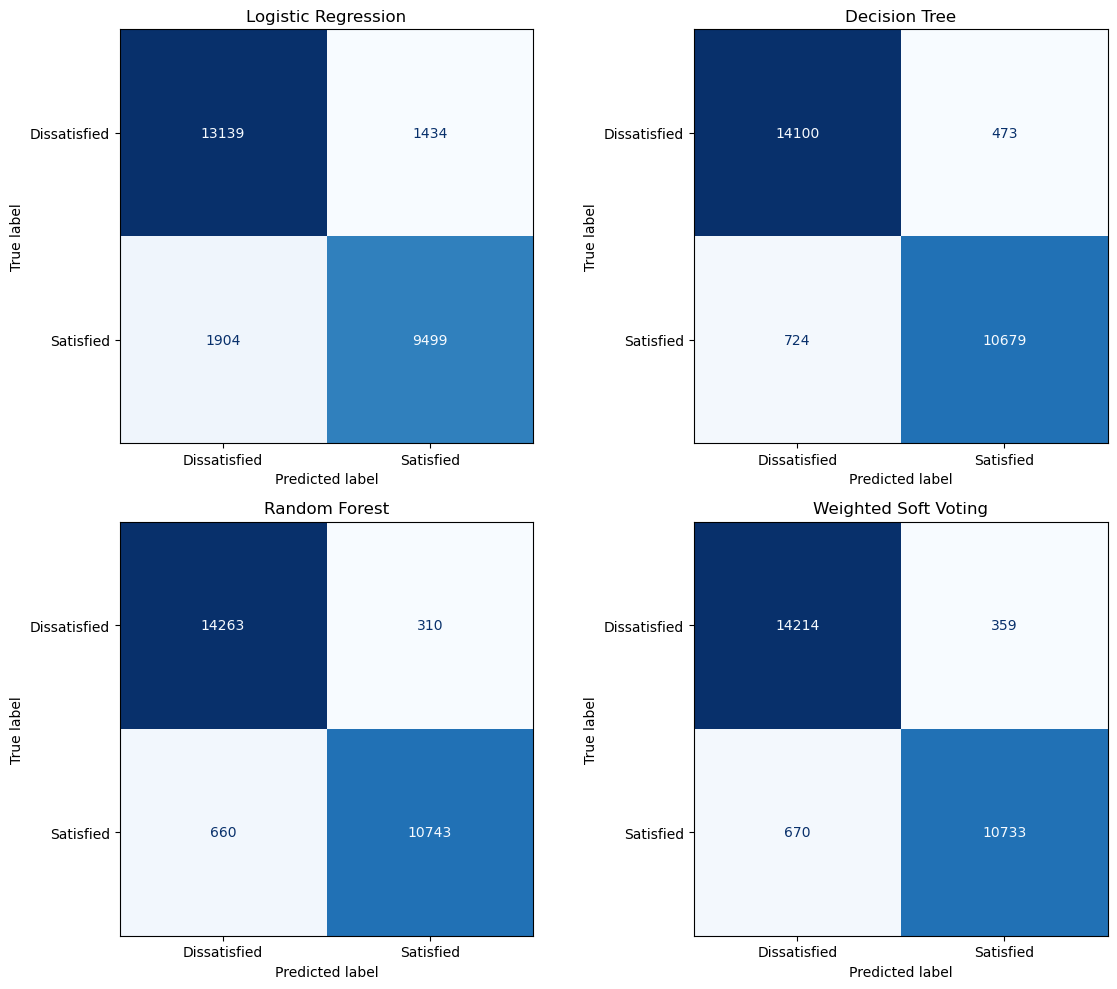

In [49]:
# Confusion matrices for all four models

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, pred) in zip(
    axes.flat, test_predictions.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        labels=[0, 1],
        display_labels=["Dissatisfied", "Satisfied"],
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

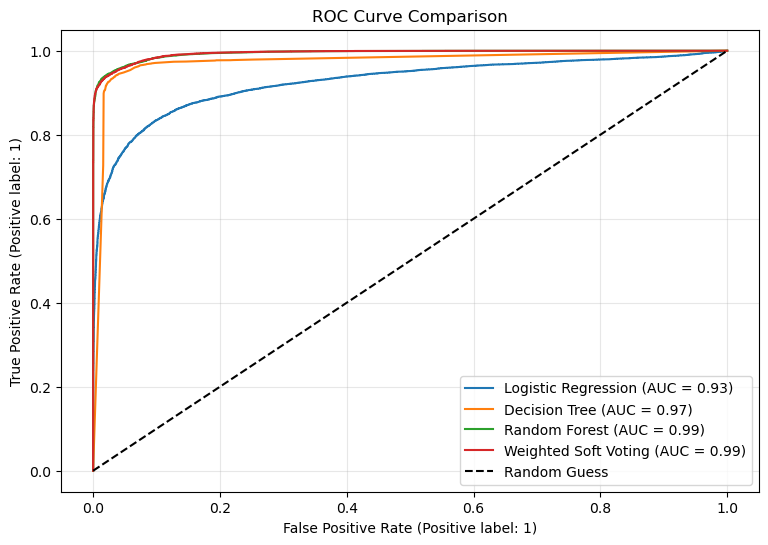

In [50]:
# ROC curves for all four models

from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))

for name, prob in test_probabilities.items():

    RocCurveDisplay.from_predictions(
        y_test,
        prob,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "k--", label="Random Guess")

plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [51]:
# Detailed classification reports

from sklearn.metrics import classification_report

for name, pred in test_predictions.items():

    print("\nMODEL:", name)

    print(
        classification_report(
            y_test,
            pred,
            labels=[0, 1],
            target_names=[
                "Dissatisfied",
                "Satisfied"
            ],
            digits=3
        )
    )


MODEL: Logistic Regression
              precision    recall  f1-score   support

Dissatisfied      0.873     0.902     0.887     14573
   Satisfied      0.869     0.833     0.851     11403

    accuracy                          0.871     25976
   macro avg      0.871     0.867     0.869     25976
weighted avg      0.871     0.871     0.871     25976


MODEL: Decision Tree
              precision    recall  f1-score   support

Dissatisfied      0.951     0.968     0.959     14573
   Satisfied      0.958     0.937     0.947     11403

    accuracy                          0.954     25976
   macro avg      0.954     0.952     0.953     25976
weighted avg      0.954     0.954     0.954     25976


MODEL: Random Forest
              precision    recall  f1-score   support

Dissatisfied      0.956     0.979     0.967     14573
   Satisfied      0.972     0.942     0.957     11403

    accuracy                          0.963     25976
   macro avg      0.964     0.960     0.962     25976
we

In [52]:
# Statistical comparison: Random Forest vs Ensemble

import numpy as np
from scipy.stats import binomtest

rf_correct = (
    test_predictions["Random Forest"] == np.asarray(y_test)
)

ensemble_correct = (
    test_predictions[best_ensemble_name] == np.asarray(y_test)
)

# Cases where only one model is correct
rf_only = np.sum(rf_correct & ~ensemble_correct)

ensemble_only = np.sum(~rf_correct & ensemble_correct)

total = rf_only + ensemble_only

# McNemar's exact test
p_value = (
    binomtest(rf_only, total, p=0.5).pvalue
    if total > 0 else 1.0
)

print("Random Forest only correct:", rf_only)
print("Ensemble only correct:", ensemble_only)
print("P-value:", round(p_value, 5))

if p_value < 0.05:
    print("Statistically significant difference in accuracy")
else:
    print("No statistically significant difference in accuracy")

Random Forest only correct: 215
Ensemble only correct: 156
P-value: 0.00256
Statistically significant difference in accuracy


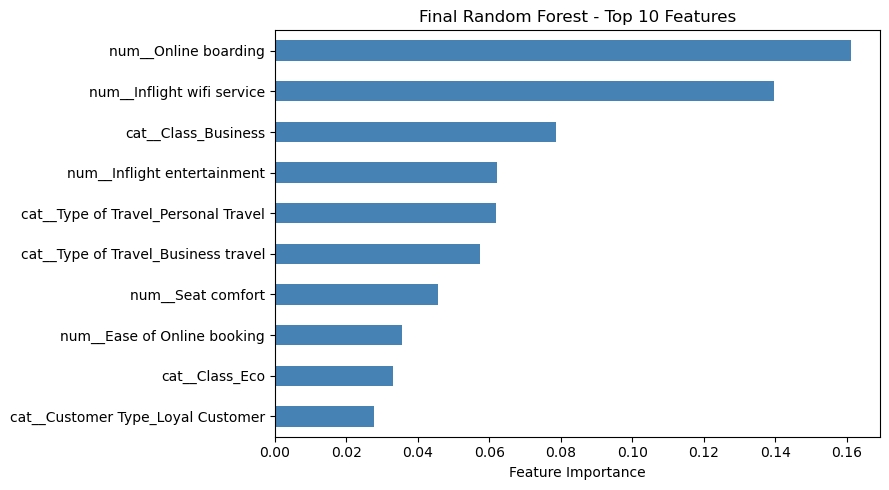

Recommended model: Random Forest


In [53]:
# Feature importance of final Random Forest

rf_model = final_models["Random Forest"]

feature_names = rf_model.named_steps[
    "preprocessing"
].get_feature_names_out()

importance = rf_model.named_steps[
    "classifier"
].feature_importances_

top_features = pd.Series(
    importance,
    index=feature_names
).nlargest(10)

top_features.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Final Random Forest - Top 10 Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

print("Recommended model: Random Forest")

In [54]:
# Verify processed datasets

processed_train_check = pd.read_csv("data/processed_train.csv")
processed_test_check = pd.read_csv("data/processed_test.csv")

print("Processed training:", processed_train_check.shape)
print("Processed testing:", processed_test_check.shape)

print(
    "Columns match:",
    processed_train_check.columns.equals(
        processed_test_check.columns
    )
)

Processed training: (103904, 29)
Processed testing: (25976, 29)
Columns match: True


In [55]:
# Check CSV file sizes

from pathlib import Path

for file in Path("data").glob("*.csv"):
    size = file.stat().st_size / (1024 * 1024)
    print(file.name, ":", round(size, 2), "MB")

processed_test.csv : 4.47 MB
processed_train.csv : 17.87 MB
test.csv : 2.9 MB
train.csv : 11.63 MB
